# Chapter 10 — Clustering Techniques

**Book:** scikit-learn Cookbook, Third Edition — John Sukup (Packt Publishing, 2025)

This notebook follows the chapter sequence and demonstrates the core methods through executable examples. Numerical results appear immediately below the code, followed by a discussion of how to read them. The code examples are self-contained educational reproductions and extensions, not a word-for-word transcription of the text.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
np.set_printoptions(precision=3, suppress=True)
RANDOM_STATE=42

## 1. 1. Introduction to clustering

Clustering is an unsupervised task that attempts to group observations with similar feature patterns. Unlike classification, there are no supplied class labels during fitting.

In [2]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
X,_=make_blobs(n_samples=300,centers=3,cluster_std=.75,random_state=22)
Xs=StandardScaler().fit_transform(X)
print('Number of examples:',len(Xs),'Number of features:',Xs.shape[1])

Number of examples: 300 Number of features: 2


**Interpretation.** The points have two numeric features, making them suitable for a visual demonstration. Any clusters recovered by an algorithm depend on its assumptions and configuration.

## 2. 2. K-means clustering

K-means assigns points to the nearest centroid and repeatedly updates centroids to reduce within-cluster squared distances.

In [3]:
from sklearn.cluster import KMeans
km=KMeans(n_clusters=3,n_init=10,random_state=42).fit(Xs)
print('Cluster sizes:',np.bincount(km.labels_))
print('Inertia:',round(km.inertia_,3))
print('Centroids:',km.cluster_centers_.round(2))

Cluster sizes: [107 100  93]
Inertia: 41.655
Centroids: [[-0.49 -0.36]
 [ 1.32  1.34]
 [-0.86 -1.03]]


**Interpretation.** Cluster labels are arbitrary identifiers; label 0 is not inherently better than label 1. Inertia summarizes within-cluster spread but naturally decreases as more clusters are added.

## 3. 3. Selecting the number of clusters

The silhouette score compares within-cluster cohesion with separation from other clusters. It is one of several ways to inspect a candidate number of groups.

In [4]:
from sklearn.metrics import silhouette_score
for k in range(2,7):
    m=KMeans(n_clusters=k,n_init=10,random_state=42).fit(Xs)
    print('k=',k,'silhouette=',round(silhouette_score(Xs,m.labels_),3))

k= 2 silhouette= 0.784
k= 3 silhouette= 0.588
k= 4 silhouette= 0.458
k= 5 silhouette= 0.427
k= 6 silhouette= 0.398


**Interpretation.** Larger silhouette values suggest more compact and separated clusters under the chosen metric. The score should be interpreted with subject-matter needs rather than treated as an automatic truth.

## 4. 4. Hierarchical clustering

Agglomerative clustering merges observations or groups progressively according to a linkage rule. It offers a different view of structure from centroid-based K-means.

In [5]:
from sklearn.cluster import AgglomerativeClustering
for linkage in ['ward','complete','average']:
    lab=AgglomerativeClustering(n_clusters=3,linkage=linkage).fit_predict(Xs)
    print(linkage,'silhouette',round(silhouette_score(Xs,lab),3))

ward silhouette 0.587
complete silhouette 0.514
average silhouette 0.592


**Interpretation.** Different linkage choices can create different group shapes. Ward linkage is specifically based on limiting increases in within-cluster variance.

## 5. 5. Density-based clustering with DBSCAN

DBSCAN builds clusters from dense neighborhoods and labels points outside sufficiently dense areas as noise. It does not require the number of clusters in advance.

In [6]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN
Xm,_=make_moons(n_samples=300,noise=.07,random_state=42)
for eps in [.12,.2,.35]:
    labels=DBSCAN(eps=eps,min_samples=5).fit_predict(Xm)
    clusters=len(set(labels))-(1 if -1 in labels else 0)
    print('eps',eps,'clusters',clusters,'noise points',sum(labels==-1))

eps 0.12 clusters 4 noise points 16
eps 0.2 clusters 2 noise points 0
eps 0.35 clusters 1 noise points 0


**Interpretation.** Smaller eps can fragment the data or mark more points as noise. The appropriate neighborhood radius depends heavily on scaling and data density.

## 6. 6. Comparing clustering algorithms

Algorithms embody different notions of a group. Visual inspection can help when data have only two features.

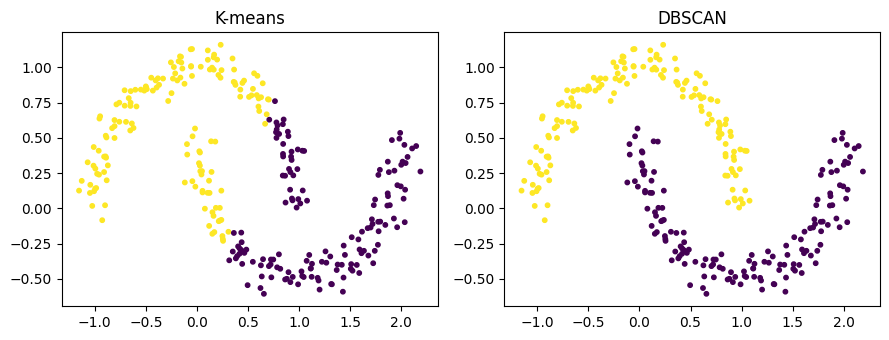

In [7]:
import matplotlib.pyplot as plt
labs1=KMeans(n_clusters=2,n_init=10,random_state=0).fit_predict(Xm)
labs2=DBSCAN(eps=.2,min_samples=5).fit_predict(Xm)
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
axes[0].scatter(Xm[:,0],Xm[:,1],c=labs1,s=10);axes[0].set_title('K-means')
axes[1].scatter(Xm[:,0],Xm[:,1],c=labs2,s=10);axes[1].set_title('DBSCAN')
plt.tight_layout();plt.show()

**Interpretation.** K-means divides space around centroids, whereas DBSCAN can follow curved dense structures. That distinction is particularly clear on the two-moons example.

## 7. Creating an unlabeled dataset

Clustering looks for similarity patterns without using target labels during fitting.

Data shape: (260, 2)


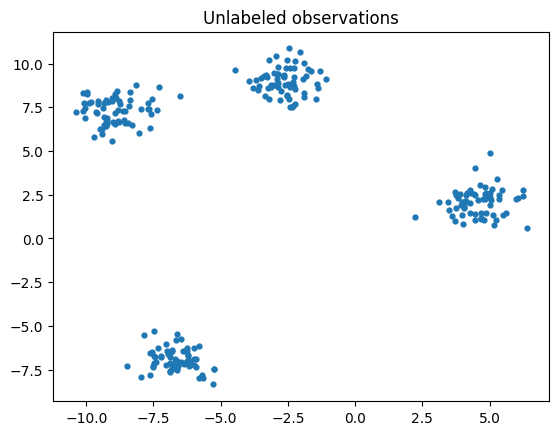

In [8]:
from sklearn.datasets import make_blobs
Xc,_=make_blobs(n_samples=260,centers=4,cluster_std=.75,random_state=42)
print('Data shape:',Xc.shape);plt.scatter(Xc[:,0],Xc[:,1],s=12);plt.title('Unlabeled observations');plt.show()

**Interpretation.** The scatterplot suggests multiple dense regions. The center labels used to generate the dataset are discarded before model fitting.

## 8. K-means centroids and assignments

K-means assigns each point to its nearest centroid and updates the centroid until assignments stabilize.

In [9]:
from sklearn.cluster import KMeans
kc=KMeans(n_clusters=4,n_init=10,random_state=42).fit(Xc)
print('Inertia:',round(kc.inertia_,2),'sizes:',np.bincount(kc.labels_));print(kc.cluster_centers_.round(2))

Inertia: 275.18 sizes: [65 65 65 65]
[[-8.92  7.29]
 [-6.69 -6.92]
 [ 4.59  2.09]
 [-2.63  8.99]]


**Interpretation.** Centroids summarize cluster locations, and cluster sizes indicate their relative frequency. Inertia measures within-group compactness on the selected feature scale.

## 9. Visualizing K-means boundaries

K-means creates Voronoi-style regions around centroids in Euclidean space.

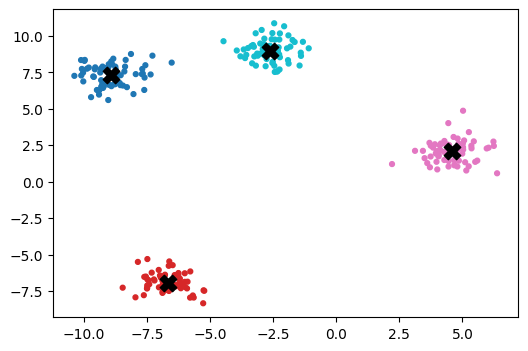

In [10]:
plt.figure(figsize=(6,4));plt.scatter(Xc[:,0],Xc[:,1],c=kc.labels_,s=12,cmap='tab10');plt.scatter(kc.cluster_centers_[:,0],kc.cluster_centers_[:,1],marker='X',c='black',s=140);plt.show()

**Interpretation.** Every observation receives a cluster label; centroid markers show the learned representative positions. Colors are identifiers and do not imply ranking.

## 10. Elbow curve for K

Within-cluster inertia decreases as more centroids are added, so the elbow heuristic inspects the rate of improvement.

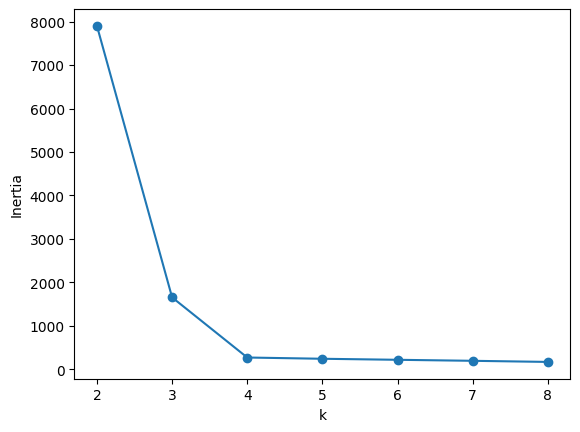

In [11]:
ks=list(range(2,9));vals=[KMeans(n_clusters=k,n_init=10,random_state=42).fit(Xc).inertia_ for k in ks]
plt.plot(ks,vals,'o-');plt.xlabel('k');plt.ylabel('Inertia');plt.show()

**Interpretation.** The curve often bends near a useful k, but the elbow is not guaranteed or uniquely defined. Domain knowledge should complement the plot.

## 11. Silhouette score

The silhouette statistic compares a point’s distance to its own group with distances to nearby other groups.

In [12]:
from sklearn.metrics import silhouette_score
for k in range(2,8):
 lab=KMeans(n_clusters=k,n_init=10,random_state=42).fit_predict(Xc)
 print(k,round(silhouette_score(Xc,lab),3))

2 0.609
3 0.782
4 0.842
5 0.72
6 0.604
7 0.474


**Interpretation.** Larger values generally suggest more cohesive and separated clusters; however, silhouette tends to favor compact shapes and should not be treated as universal truth.

## 12. Feature scale sensitivity

Distance-based cluster assignments can change if one feature has a much larger numeric range.

In [13]:
from sklearn.metrics import adjusted_rand_score
Xshift=np.column_stack([Xc[:,0]*100,Xc[:,1]])
a=KMeans(n_clusters=4,n_init=10,random_state=42).fit_predict(Xshift)
b=KMeans(n_clusters=4,n_init=10,random_state=42).fit_predict(StandardScaler().fit_transform(Xshift))
print('Adjusted Rand index:',round(adjusted_rand_score(a,b),3))

Adjusted Rand index: 0.896


**Interpretation.** The agreement statistic measures how strongly the partitions differ. Scaling is essential to review whenever features have different units.

## 13. Agglomerative clustering and dendrogram

Hierarchical clustering merges nearby groups repeatedly. Linkage records the merge history and its distance.

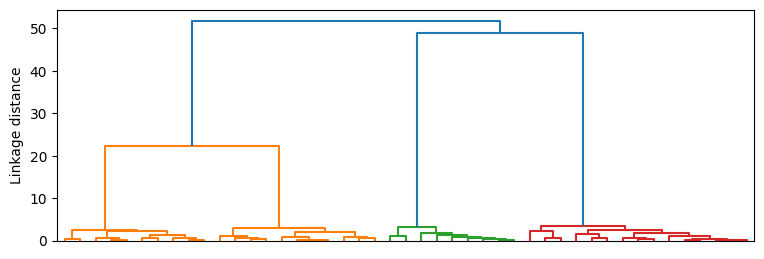

In [14]:
from scipy.cluster.hierarchy import linkage,dendrogram
L=linkage(Xc[:45],method='ward')
plt.figure(figsize=(9,3));dendrogram(L,no_labels=True);plt.ylabel('Linkage distance');plt.show()

**Interpretation.** A dendrogram visualizes how many and which groups appear as the cut height varies. Large vertical gaps indicate relatively distinct merge stages.

## 14. Comparing hierarchical linkage

Single, complete, average and Ward linkage define distinct group merging rules.

In [15]:
from sklearn.cluster import AgglomerativeClustering
for method in ['single','complete','average','ward']:
 labels=AgglomerativeClustering(n_clusters=4,linkage=method).fit_predict(Xc)
 print(method,'sizes:',np.bincount(labels),'silhouette:',round(silhouette_score(Xc,labels),3))

single sizes: [65 65 65 65] silhouette: 0.842
complete sizes: [65 65 65 65] silhouette: 0.842
average sizes: [65 65 65 65] silhouette: 0.842
ward sizes: [65 65 65 65] silhouette: 0.842


**Interpretation.** Distinct linkage rules can yield different partitions on the same data. Ward generally emphasizes compact clusters, whereas single linkage can connect chains.

## 15. DBSCAN on nonlinear shapes

DBSCAN groups connected dense regions and can label noise observations with -1.

DBSCAN labels: (array([0, 1]), array([130, 130]))


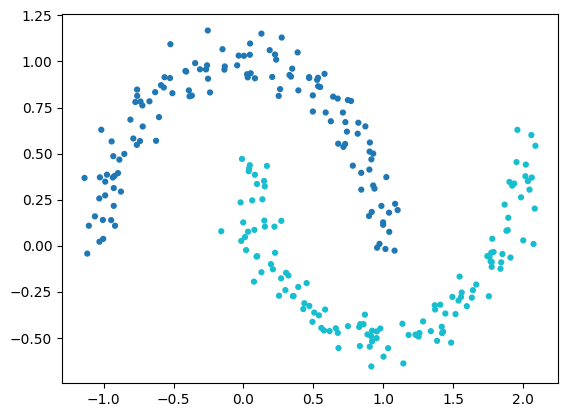

In [16]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN
Xm,_=make_moons(n_samples=260,noise=.07,random_state=42)
db=DBSCAN(eps=.20,min_samples=5).fit(Xm)
print('DBSCAN labels:',np.unique(db.labels_,return_counts=True));plt.scatter(Xm[:,0],Xm[:,1],c=db.labels_,cmap='tab10',s=12);plt.show()

**Interpretation.** DBSCAN follows nonconvex shapes that k-means can struggle with. The -1 label marks samples classified as noise rather than a separate ordinary cluster.

## 16. DBSCAN parameter sensitivity

The density threshold eps and min_samples determine how readily DBSCAN connects observations into groups.

In [17]:
for eps in [.10,.18,.26,.40]:
 lab=DBSCAN(eps=eps,min_samples=5).fit_predict(Xm)
 print('eps',eps,'clusters',len(set(lab)-{-1}),'noise',int((lab==-1).sum()))

eps 0.1 clusters 15 noise 59
eps 0.18 clusters 2 noise 1
eps 0.26 clusters 2 noise 0
eps 0.4 clusters 1 noise 0


**Interpretation.** Smaller eps generally creates more noise and may fragment clusters; larger eps can merge previously distinct shapes. Choosing parameters requires inspecting the data scale.

## 17. Gaussian mixture soft memberships

GMM models data as multiple probability distributions rather than strictly nearest-centroid regions.

In [18]:
from sklearn.mixture import GaussianMixture
gmm=GaussianMixture(n_components=4,random_state=42).fit(Xc)
print('Weights:',gmm.weights_.round(3));print('First memberships:\n',gmm.predict_proba(Xc[:4]).round(3))

Weights: [0.25 0.25 0.25 0.25]
First memberships:
 [[0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]]


**Interpretation.** Probability rows sum to one, allowing ambiguous observations to have partial membership in more than one component.

## 18. Model selection with BIC

The Bayesian information criterion penalizes overly complex probabilistic mixture models.

In [19]:
for k in range(1,8):
 g=GaussianMixture(n_components=k,random_state=42).fit(Xc)
 print(k,round(g.bic(Xc),1))

1 3311.2
2 2675.1
3 2159.4
4 1982.0
5 2013.2


6 2037.7


7 2065.3


**Interpretation.** Lower BIC reflects a better fit-complexity balance for the same dataset. It should not be confused with classification accuracy.

## 19. Clustering evaluation with a known reference

External metrics can be used when labels exist for benchmarking, though the labels must not be used during unsupervised fitting.

In [20]:
from sklearn.datasets import make_blobs
Xe,ye=make_blobs(n_samples=260,centers=4,random_state=42,cluster_std=.75)
from sklearn.metrics import adjusted_rand_score,normalized_mutual_info_score
pred=KMeans(n_clusters=4,n_init=10,random_state=42).fit_predict(Xe)
print('ARI:',round(adjusted_rand_score(ye,pred),3),'NMI:',round(normalized_mutual_info_score(ye,pred),3))

ARI: 1.0 NMI: 1.0


**Interpretation.** ARI and normalized mutual information summarize agreement after ignoring arbitrary cluster numbering. High scores here reflect a deliberately separable synthetic dataset.

## 20. Clustering high-dimensional data using PCA

Dimensionality reduction may help visualize high-dimensional structure or reduce noise before clustering.

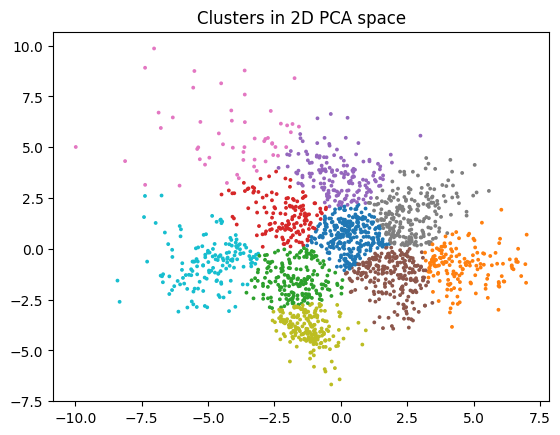

In [21]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
D=load_digits().data
D2=PCA(n_components=2,random_state=42).fit_transform(StandardScaler().fit_transform(D))
labels=KMeans(n_clusters=10,n_init=10,random_state=42).fit_predict(D2)
plt.scatter(D2[:,0],D2[:,1],c=labels,s=3,cmap='tab10');plt.title('Clusters in 2D PCA space');plt.show()

**Interpretation.** A two-dimensional PCA projection can lose important class structure. K-means clusters in this projection should not automatically be interpreted as true digit categories.